# Fichas de emergencia con código QR
## Solemne I · Programación II (INGO002) · Universidad San Sebastián

**Contraparte:** Fundación Sin Barreras
**Integrantes:** _(completar)_
**Repositorio:** https://github.com/YasniiSS/fundacion_sin_barreras_v2

> Todo el prototipo usa **datos ficticios**.

### Contenido
1. Contexto y objetivo
2. Estructura del proyecto (programación modular)
3. Instalación
4. Fuente de datos y carga inicial
5. Privacidad y consentimiento
6. Validación de registros
7. Carpetas por participante
8. Fichas HTML
9. Publicación en línea
10. Generación masiva de QR
11. Pruebas del prototipo
12. Manual de uso y mantenimiento
13. Pasos manuales y límites
14. Propuesta de implementación física
15. Autoevaluación
16. Declaración de uso de inteligencia artificial

## 1. Contexto y objetivo

Algunas personas autistas pueden sufrir **extravíos involuntarios**, por ejemplo por sobrecarga sensorial.
En esa situación pueden tener dificultades para comunicarse: ser no verbales, olvidar el lenguaje bajo estrés
o usar comunicación alternativa.

**Objetivo:** que cualquier persona que encuentre a un participante pueda escanear un código QR y ver,
sin iniciar sesión, **a quién llamar** y **cómo ayudarlo con respeto**.

**Flujo del prototipo:**

```
bbdd.csv / formulario  →  participantes.csv  →  carpeta por persona  →  ficha HTML
                                                                         ↓
                          celular escanea  ←  código QR  ←  publicación en GitHub Pages
```

## 2. Estructura del proyecto (programación modular)

```
fundacion_sin_barreras_v2/
├── reporte_solemne1.ipynb   ← este reporte
├── README.md                ← instrucciones rápidas
├── requirements.txt         ← dependencias
├── src/                     ← código (un módulo por tarea)
│   ├── config.py            ← rutas, URL de publicación, campos del CSV
│   ├── datos.py             ← leer/escribir/validar el CSV
│   ├── carga.py             ← carga inicial desde bbdd.csv
│   ├── formulario.py        ← registro con input()
│   ├── carpetas.py          ← una carpeta por participante
│   ├── fichas.py            ← ficha HTML por participante
│   ├── qr.py                ← QR por lotes + verificación
│   └── main.py              ← ejecuta todo en orden
├── datos/                   ← PRIVADO (no se sube al repositorio público)
│   ├── bbdd.csv             ← datos originales
│   ├── participantes.csv    ← fuente oficial del proceso
│   └── log_proceso.txt      ← qué se procesó y qué se omitió
├── participantes/           ← PRIVADO: una carpeta por persona (ficha + QR)
├── docs/                    ← PÚBLICO: lo único que publica GitHub Pages
│   ├── index.html           ← portada SIN lista de participantes
│   └── p/<uuid>.html        ← fichas públicas
└── evidencias/              ← capturas de las pruebas
```

| Módulo | Qué hace | Recibe | Entrega | Usa |
|---|---|---|---|---|
| `config.py` | Guarda rutas, URL de publicación y campos | — | Constantes | — |
| `datos.py` | Lee y escribe el CSV, busca por RUT, valida y clasifica registros | Ruta del CSV | Válidos, retirados y omitidos | `config` |
| `carga.py` | Convierte `bbdd.csv` al formato del proyecto, sin duplicar | `bbdd.csv` | Filas nuevas en `participantes.csv` | `datos`, `config` |
| `formulario.py` | Pide datos con `input()`, consentimiento, valida y guarda | Respuestas del usuario | Registro creado o actualizado | `datos`, `config` |
| `carpetas.py` | Limpia nombres y crea una carpeta por persona | Un registro | Ruta de la carpeta | `config` |
| `fichas.py` | Genera la ficha HTML y verifica que sea de la persona correcta | Un registro | `ficha.html` y `docs/p/<uuid>.html` | `config` |
| `qr.py` | Construye la URL con el UUID, genera y lee los QR | Lista de registros | Imágenes `.png` | `carpetas`, `fichas`, `config` |
| `main.py` | Ejecuta todo en orden y escribe el log | — | Carpetas, fichas, QR, log | Todos |

**Reglas que seguimos:** cada función hace una sola cosa, las rutas viven solo en `config.py`,
cada módulo tiene un docstring con *Responsabilidad, Decisiones y Funciones*, y `main.py` no tiene lógica propia.

In [1]:
# Cada módulo describe su responsabilidad y decisiones en su docstring:
import src.carpetas
print(src.carpetas.__doc__)


carpetas.py
Gestión de carpetas por participante.

Responsabilidad:
    Crear una carpeta por cada participante dentro de participantes/,
    con un nombre seguro para cualquier sistema operativo.

Decisiones:
    - El nombre de la carpeta combina nombres, apellidos y UUID:
      jose_tomas_arriagada_penaloza_3f9c2e1a
      Así dos personas con el mismo nombre nunca comparten carpeta.
    - Se quitan tildes, ñ, espacios y símbolos con unicodedata.
    - El registro se relaciona con su carpeta por el UUID (final del nombre).
      Si la persona corrige su nombre, la carpeta se renombra: no se crea
      una segunda carpeta ni se pierden los archivos.
    - Si la carpeta ya existe, se reutiliza. Nunca se borra nada.

Funciones:
    limpiar_nombre(texto)        -> str
    nombre_carpeta(registro)     -> str
    buscar_carpeta_por_uuid(uuid) -> Path | None
    crear_carpeta(registro)      -> (Path, estado)



## 3. Instalación

Requisitos: **Python 3.10 o superior**.

```bash
git clone https://github.com/YasniiSS/fundacion_sin_barreras_v2.git
cd fundacion_sin_barreras_v2
pip install -r requirements.txt
```

| Dependencia | Para qué |
|---|---|
| `qrcode[pil]` | Generar los códigos QR |
| `Pillow` | Escribir el nombre bajo cada QR |
| `opencv-python-headless` | Leer los QR generados para verificarlos |
| `notebook` | Abrir este reporte |
| `csv`, `os`, `pathlib`, `uuid`, `unicodedata`, `html` | Incluidos en Python |

In [2]:
import sys, qrcode, PIL, cv2
print("Python:", sys.version.split()[0])
print("Pillow:", PIL.__version__, "| OpenCV:", cv2.__version__, "| qrcode: OK")

Python: 3.13.14
Pillow: 12.3.0 | OpenCV: 5.0.0 | qrcode: OK


### Reinicio de la demostración

La siguiente celda deja el proyecto **como recién descargado**: borra `participantes.csv`, el log, las carpetas
de participantes y las fichas públicas. **No toca `bbdd.csv`**.
Así, cualquier persona que ejecute este notebook obtiene los mismos resultados.

> ⚠️ En un uso real con participantes, poner `REINICIAR_DEMO = False`.

In [3]:
import os, shutil
from src import config

REINICIAR_DEMO = True

if REINICIAR_DEMO:
    for archivo in (config.RUTA_CSV, config.RUTA_LOG):
        if os.path.exists(archivo):
            os.remove(archivo)
    for carpeta in (config.CARPETA_PARTICIPANTES, config.CARPETA_PUBLICA):
        if os.path.isdir(carpeta):
            shutil.rmtree(carpeta)
    print("Demostración reiniciada. bbdd.csv se conserva:", os.path.exists(config.RUTA_BBDD))

Demostración reiniciada. bbdd.csv se conserva: True


## 4. Fuente de datos y carga inicial

**Decisión:** suponemos que la información ya fue recopilada y está en una planilla, `datos/bbdd.csv`
(separada por `;`, como la exporta Excel en español). Además implementamos un **formulario con `input()`**
para incorporar o actualizar participantes.

- **Cómo se organiza:** una fila = un participante; una columna = un dato.
- **Fuente oficial:** `bbdd.csv` se importa **una vez** a `datos/participantes.csv`, que tiene todos los campos
  del proyecto. `bbdd.csv` no se modifica y queda como respaldo.
- **Cómo se reconocen repetidos:** por el **RUT normalizado** (`12.345.678-9` y `12345678-9` son el mismo).
- **Cómo se reconocen incompletos:** `datos.validar_registro()` revisa los campos obligatorios y el formato del teléfono.
- **Cómo se incorporan participantes:** con el formulario (`python -m src.formulario`) o agregando una fila
  al CSV. Si la fila no tiene UUID, el programa se lo asigna.

### Datos originales

In [4]:
import csv
with open(config.RUTA_BBDD, encoding="utf-8-sig") as f:
    filas = list(csv.reader(f, delimiter=";"))
print("Columnas:", filas[0])
print("Registros:", len(filas) - 1, "\n")
# RUT y dirección se ocultan: este notebook se publica en el repositorio.
for fila in filas[1:4]:
    fila[1] = fila[1][:2] + ".***.***-*"
    fila[5] = "*** , " + fila[5].rsplit(",", 1)[-1].strip()
    print(fila)

Columnas: ['Nombre completo', 'Rut', 'Edad', 'Condición', 'Conteción', 'Dirección', 'Nombre Contacto', 'Telefono de contacto']
Registros: 10 

['Maria Pia Alvarez Muños', '24.***.***-*', '9', 'Autismo no verbal', 'Hablar de forma pausada', '*** , Cerrillo', 'Juana Lizama', ' +569 32434609']
['Jose Tomas Arriagada Peñaloza', '25.***.***-*', '8', 'Autismo con sensibilidad a los sonidos', 'No abrazar, requiere de espacio', '*** , La Cisterna', 'Cristina Toloza', '+569 52634707']
['Santiago Andres Baquedano Silva', '23.***.***-*', '12', 'Autismo no verbal', 'En lo posible facilitar algo dulce, para calmar', '*** , La cisterna', 'Jose Luis Peñaloza', '+569 22233601']


### Problemas detectados en `bbdd.csv` y cómo se resuelven

| Problema | Ejemplo | Solución en `carga.py` |
|---|---|---|
| Nombre completo en una sola columna | `Maria Pia Alvarez Muños` | Los 2 últimos términos son apellidos |
| Dirección exacta | `El Parron #113, La Cisterna` | Se guarda en privado; solo se publica la **comuna** |
| Comuna con símbolos o minúsculas | `#La Florida`, `La cisterna` | Se limpia y se capitaliza |
| Espacios dobles o al final | `Alarcon  Muños`, `Autismo ` | Se eliminan |
| Columna con error de tipeo | `Conteción` | Se reconoce igual que "contención" |
| Teléfono con un dígito de más | `+569 425534777` | **No se corrige solo**: el registro se omite y se informa |
| Sin columna de consentimiento | — | Se simula (datos ficticios); en la realidad, autorización firmada |
| Un solo contacto y sin relación | — | El contacto 2 y la relación quedan como "No informado" |

### Columnas de `participantes.csv`

In [5]:
from src import config
privados = set(config.CAMPOS_PRIVADOS)
for campo in config.CAMPOS:
    etiqueta = "OBLIGATORIO" if campo in config.CAMPOS_OBLIGATORIOS else ""
    etiqueta += "  (privado)" if campo in privados else ""
    print(f"  {campo:<22} {etiqueta}")

  uuid                   OBLIGATORIO
  rut                    OBLIGATORIO  (privado)
  nombres                OBLIGATORIO
  apellidos              OBLIGATORIO
  edad                     (privado)
  email                    (privado)
  direccion                (privado)
  referencia_publica     OBLIGATORIO
  condicion              
  como_me_comunico       
  que_me_ayuda           
  que_evitar             
  contacto1_nombre       OBLIGATORIO
  contacto1_relacion     
  contacto1_telefono     OBLIGATORIO
  contacto2_nombre       
  contacto2_relacion     
  contacto2_telefono     
  autoriza_publicacion   
  nombre_quien_autoriza    (privado)
  fecha_registro         
  fecha_actualizacion    
  activo                 


In [6]:
from src.carga import importar_bbdd, separar_nombre, extraer_comuna

print(separar_nombre("Maria Pia Alvarez Muños"))
print(extraer_comuna("Lia Aguirre 7523, #La Florida"))
print(extraer_comuna("Avenida Ossa #2354, La cisterna"))

print("\nCarga inicial:", importar_bbdd())
print("Segunda carga (no debe duplicar):", importar_bbdd())

('Maria Pia', 'Alvarez Muños')
La Florida
La Cisterna

Carga inicial: {'importados': 10, 'ya_existian': 0, 'sin_rut': 0}
Segunda carga (no debe duplicar): {'importados': 0, 'ya_existian': 10, 'sin_rut': 0}


## 5. Privacidad y consentimiento

### Qué se publica y qué no

| Dato | ¿Se publica? | Motivo |
|---|---|---|
| Primer nombre | Sí | Permite llamar a la persona por su nombre y calmarla |
| Comuna o referencia | Sí | Orienta sin revelar dónde vive exactamente |
| Contactos de emergencia (nombre, relación, teléfono) | Sí | Es el dato más urgente |
| Condición, cómo se comunica, qué lo calma, qué evitar | Sí | Ayuda a actuar con respeto |
| Apellidos, RUT, edad, email, dirección exacta, quién autorizó | **No** | No son necesarios en una emergencia |

### Reflexiones

- **¿Dirección exacta?** No. Una dirección exacta pública, junto al nombre y la condición de un niño, es un
  riesgo. La comuna basta para orientar; el contacto de emergencia sabe dónde vive la persona.
- **¿Los contactos saben que su número será público?** El formulario lo advierte antes de pedir la autorización.
  En la implementación real, cada contacto debe aceptarlo por escrito.
- **¿Qué información ayuda a actuar con respeto?** Instrucciones concretas en primera persona:
  "cómo me comunico", "qué me ayuda", "qué evitar". No diagnósticos detallados.
- **¿Cómo pedir corrección o retiro?** Escribiendo al correo de la fundación que aparece en cada ficha.
  El equipo actualiza el registro (o lo marca como inactivo) y vuelve a ejecutar el proceso.

### Propuesta de autorización para la implementación real

1. Reunión informativa con las familias: propósito, qué se publica, quién puede verlo y por cuánto tiempo.
2. **Consentimiento informado firmado** por el tutor legal (los participantes del ejemplo son menores de edad),
   y asentimiento de la persona cuando sea posible.
3. Cada contacto de emergencia firma que acepta que su teléfono sea visible.
4. Revisión anual de los datos y derecho a retirar la ficha en cualquier momento.
5. Registro de quién autorizó y cuándo (`nombre_quien_autoriza`, `fecha_registro`).

## 6. Validación de registros

`datos.clasificar_participantes()` separa los registros en:

- **Válidos:** se publican.
- **Retirados:** sin autorización o marcados `activo = no`; se quita su ficha pública.
- **Omitidos:** incompletos o repetidos; no se publican y se informa el motivo en el log.

In [7]:
from src import datos

print(datos.normalizar_rut("12.345.678-k"), datos.normalizar_rut("12345678K"))
print(datos.normalizar_telefono("+569 32434609"), datos.telefono_es_valido("+569 32434609"))
print(datos.normalizar_telefono("+569 425534777"), datos.telefono_es_valido("+569 425534777"))

participantes = datos.leer_participantes()
validos, retirados, omitidos = datos.clasificar_participantes(participantes)
print(f"\nVálidos: {len(validos)} | Retirados: {len(retirados)} | Omitidos: {len(omitidos)}")
for registro, motivo in omitidos:
    print(f"  Omitido: {registro['nombres']} {registro['apellidos']} -> {motivo}")

12345678-K 12345678-K
+56932434609 True
+569425534777 False

Válidos: 9 | Retirados: 0 | Omitidos: 1
  Omitido: Felipe Alfredo Bustamante Castillo -> 'contacto1_telefono' inválido (+569425534777)


## 7. Carpetas por participante

- **Nombre de la carpeta:** `nombres_apellidos_uuid`, sin tildes, ñ ni espacios.
- **Relación registro ↔ carpeta:** por el **UUID** al final del nombre. Si alguien corrige su nombre,
  la carpeta se **renombra** (no se crea otra).
- **Nombres repetidos:** el UUID es distinto, así que las carpetas nunca chocan.
- **Carpeta existente:** se reutiliza; nunca se borra nada.

In [8]:
from src.carpetas import limpiar_nombre
for texto in ["José Peña Muñoz", "María  O'Higgins", "Ana-Sofía #2", "   "]:
    print(f"{texto!r:<22} -> {limpiar_nombre(texto)}")

'José Peña Muñoz'      -> jose_pena_munoz
"María  O'Higgins"     -> maria_o_higgins
'Ana-Sofía #2'         -> ana_sofia_2
'   '                  -> sin_nombre


## 8. Fichas HTML

**Formato elegido:** página HTML. Se abre en cualquier celular, el texto se adapta a la pantalla y los
teléfonos son **botones para llamar**.

**La ficha muestra solo:** el **primer nombre**, los **contactos de emergencia**, las **características** (condición, cómo se comunica, qué lo calma, qué evitar) y la **ubicación general** (comuna).

**Orden de lectura:** 1) primer nombre, 2) a quién llamar, 3) cómo ayudar, 4) ubicación general, 5) fecha de actualización.

- **Dato faltante:** se muestra "No informado".
- **Actualización:** se cambia el CSV (o se usa el formulario) y se ejecuta `main.py`; solo se reescriben las fichas que cambiaron.
- **¿La ficha es de la persona correcta?** `fichas.verificar_ficha()` revisa que el archivo tenga el UUID,
  el nombre y el teléfono de esa persona, y que **no** muestre datos privados.
- La ficha tiene `noindex` para que no aparezca en Google.

## 9. Publicación en línea

**Herramienta:** GitHub Pages, que publica la carpeta `docs/` del repositorio.

| Ventajas | Limitaciones |
|---|---|
| Gratis, sin iniciar sesión para ver | Solo muestra archivos: no ejecuta Python ni recibe formularios |
| URL estable: el QR no cambia | Cada cambio requiere `git push` (paso manual) |
| Historial de versiones | Con plan gratuito el repositorio debe ser público |

**Cómo evitamos publicar la fuente de datos:** `.gitignore` excluye `datos/` y `participantes/`.
Solo `docs/` llega a internet. `docs/index.html` **no lista** a los participantes.

**URL de cada ficha:** `https://yasniiss.github.io/fundacion_sin_barreras_v2/p/<uuid>.html`. Lleva solo el UUID:
no revela el nombre y no se puede adivinar la de otra persona.

## 10. Generación masiva de QR

- Un QR por participante, generado **por lotes** en `qr.generar_qr_lote()`.
- Contiene la URL construida con el **UUID**: si se actualiza la ficha, **el mismo QR sigue sirviendo**.
- Bajo cada código se imprime **solo el UUID**, sin nombre: el QR va en la ropa o en una pulsera y un desconocido no debe ver datos sin escanearlo.
- El equipo sabe a quién pertenece cada QR porque el archivo se llama `qr_<nombre>_<uuid>.png`, se guarda en la carpeta de la persona y la hoja `participantes/qr_imprimir.html` (privada) muestra el nombre junto a cada código.
- `qr.verificar_qr()` **lee** cada imagen (con OpenCV, como un celular) y comprueba que contiene la URL de esa misma persona.

## 11. Pruebas del prototipo

Cada prueba registra **qué esperábamos**, **qué obtuvimos** y **la evidencia**. Al final hay una tabla resumen.

In [9]:
import glob
from IPython.display import HTML, Image, display
from src import datos, config
from src.main import procesar
from src.formulario import registrar_participante, retirar_participante, respuestas_simuladas
from src.carpetas import buscar_carpeta_por_uuid
from src.fichas import generar_html
from src.qr import url_participante, leer_qr

pruebas = []
def registrar_prueba(prueba, esperado, obtenido, ok):
    pruebas.append({"prueba": prueba, "esperado": esperado, "obtenido": obtenido,
                    "resultado": "✅ Cumple" if ok else "❌ No cumple"})
    print(("✅ CUMPLE" if ok else "❌ NO CUMPLE"), "-", prueba)

def contar_carpetas():
    return sum(1 for c in config.CARPETA_PARTICIPANTES.iterdir() if c.is_dir())  # solo carpetas, no qr_imprimir.html

def por_rut(rut):
    return datos.buscar_por_rut(datos.leer_participantes(), rut)

### Prueba 1 · Procesamiento inicial

**Esperado:** se leen los 10 registros de `bbdd.csv`; se crean 9 carpetas, 9 fichas y 9 QR.
Felipe Bustamante se **omite** porque su teléfono tiene un dígito de más.

In [10]:
r1 = procesar()
ok = (len(r1["procesados"]) == 9 and len(r1["omitidos"]) == 1 and contar_carpetas() == 9
      and not r1["errores_verificacion"])
registrar_prueba("1. Procesamiento inicial",
                 "9 carpetas/fichas/QR; 1 omitido (teléfono inválido)",
                 f"{len(r1['procesados'])} procesados, {len(r1['omitidos'])} omitido, {contar_carpetas()} carpetas",
                 ok)


Procesados: 9
  f117e6a8  Maria Pia Alvarez Muños                carpeta=creada     ficha=nueva       qr=nuevo
  60dae5fa  Jose Tomas Arriagada Peñaloza          carpeta=creada     ficha=nueva       qr=nuevo
  9e37d5b6  Santiago Andres Baquedano Silva        carpeta=creada     ficha=nueva       qr=nuevo
  f47b45bf  Rodrigo Ariel Torres Campos            carpeta=creada     ficha=nueva       qr=nuevo
  7f4f6cdc  Daniela Ignacia Flores Gatica          carpeta=creada     ficha=nueva       qr=nuevo
  ec89ab5a  Gustavo Alfonso Alarcon Muños          carpeta=creada     ficha=nueva       qr=nuevo
  46c0efae  Victor Ignacio Barriga Gutierrez       carpeta=creada     ficha=nueva       qr=nuevo
  7b68e2a3  Mateo Alfonso Berrios Fuente           carpeta=creada     ficha=nueva       qr=nuevo
  985d7ee6  Francisca Javiera Silva Jara           carpeta=creada     ficha=nueva       qr=nuevo

Omitidos (no se publican): 1
  Felipe Alfredo Bustamante Castillo: 'contacto1_telefono' inválido (+569425534777

In [11]:
# Evidencia: estructura generada
for nombre in sorted(os.listdir(config.CARPETA_PARTICIPANTES))[:3]:
    print(nombre + "/", os.listdir(config.CARPETA_PARTICIPANTES / nombre))
print("...")
print("\nFichas públicas en docs/p/:", sorted(os.listdir(config.CARPETA_PUBLICA)))

daniela_ignacia_flores_gatica_7f4f6cdc/ ['ficha.html', 'qr_daniela_ignacia_flores_gatica_7f4f6cdc.png']
francisca_javiera_silva_jara_985d7ee6/ ['ficha.html', 'qr_francisca_javiera_silva_jara_985d7ee6.png']
gustavo_alfonso_alarcon_munos_ec89ab5a/ ['ficha.html', 'qr_gustavo_alfonso_alarcon_munos_ec89ab5a.png']
...

Fichas públicas en docs/p/: ['46c0efae.html', '60dae5fa.html', '7b68e2a3.html', '7f4f6cdc.html', '985d7ee6.html', '9e37d5b6.html', 'ec89ab5a.html', 'f117e6a8.html', 'f47b45bf.html']


In [12]:
# Evidencia: ficha de un participante tal como se ve en un celular
maria = por_rut("24892743-3")
import html
ficha = html.escape(generar_html(maria), quote=True)
import warnings
with warnings.catch_warnings():  # oculta un aviso de IPython sobre iframes
    warnings.simplefilter('ignore')
    display(HTML(f'<iframe srcdoc="{ficha}" width="380" height="720" style="border:1px solid #ccc;border-radius:12px"></iframe>'))

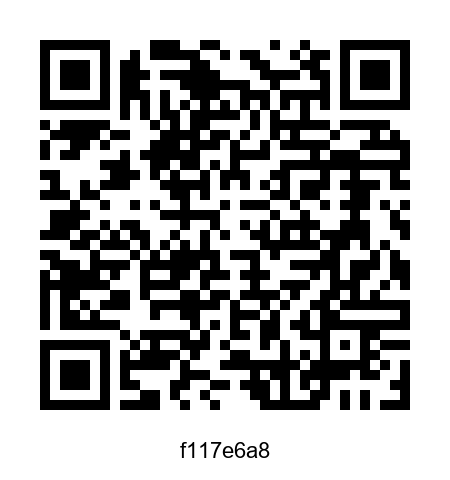

Contenido leído del QR: https://yasniiss.github.io/fundacion_sin_barreras_v2/p/f117e6a8.html
URL esperada:           https://yasniiss.github.io/fundacion_sin_barreras_v2/p/f117e6a8.html


In [13]:
# Evidencia: su QR, y lo que contiene al leerlo
carpeta_maria = buscar_carpeta_por_uuid(maria["uuid"])
qr_maria = glob.glob(str(carpeta_maria / "qr_*.png"))[0]
display(Image(qr_maria, width=220))
print("Contenido leído del QR:", leer_qr(qr_maria))
print("URL esperada:          ", url_participante(maria))

### Prueba 1b · Volver a ejecutar sin cambios

**Esperado:** no se crean carpetas nuevas; todas quedan como `existente`, y las fichas y QR `sin cambios`.

In [14]:
r1b = procesar(mostrar=False)
ok = (contar_carpetas() == 9 and all(p["carpeta_estado"] == "existente" and p["ficha_estado"] == "sin cambios"
                                    and p["qr_estado"] == "sin cambios" for p in r1b["procesados"]))
registrar_prueba("1b. Re-ejecución sin cambios", "9 carpetas existentes, nada se reescribe",
                 f"{contar_carpetas()} carpetas; estados: {set((p['carpeta_estado'], p['ficha_estado'], p['qr_estado']) for p in r1b['procesados'])}",
                 ok)

✅ CUMPLE - 1b. Re-ejecución sin cambios


### Prueba 2 · Incorporación de una persona (formulario)

Se usa el formulario real con **respuestas simuladas** (así la prueba se puede repetir).
El nombre tiene tildes y ñ a propósito.

**Esperado:** se crea el registro con un UUID nuevo, una carpeta `ana_sofia_munoz_perez_<uuid>`, su ficha y su QR.

In [15]:
respuestas = [
    "s", "Carolina Pérez",                    # consentimiento y quién autoriza
    "30.111.222-3",                           # RUT
    "Ana Sofía", "Muñoz Pérez", "8", "",      # nombres, apellidos, edad, email
    "Pasaje Los Aromos 123, Huechuraba", "",  # dirección (privada), comuna (Enter = sugerida)
    "Autismo", "Usa pictogramas y lenguaje de señas",
    "Audífonos con cancelación de ruido", "No tocar sin avisar; evitar lugares con mucho ruido",
    "Carolina Pérez", "Madre", "+56 9 8765 4321",   # contacto 1
    "Luis Muñoz", "Padre", "912345678",             # contacto 2
    "s",                                            # guardar
]
registrar_participante(leer=respuestas_simuladas(respuestas))


--- Consentimiento ---
Se publicará una ficha de emergencia en internet, visible para
cualquier persona que escanee el código QR. La ficha mostrará:
  - Solo el primer nombre (sin apellidos)
  - Contactos de emergencia y sus teléfonos
  - Características: condición y cómo ayudar a la persona
  - Ubicación general: comuna o punto de referencia (NO la dirección exacta)
NO se publicarán: apellidos, RUT, edad, email ni dirección exacta.
Para corregir o retirar la ficha: contacto@fundacion-ficticia.cl
Los contactos de emergencia deben saber que su número será visible.

¿La persona o su tutor legal autoriza la publicación? (s/n): s
Nombre de quien autoriza (persona o tutor): Carolina Pérez
RUT (ej: 12.345.678-9): 30.111.222-3
Nombres: Ana Sofía
Apellidos: Muñoz Pérez
Edad (opcional): 8
Email de contacto (opcional): 
Dirección (privada, no se publica): Pasaje Los Aromos 123, Huechuraba
Comuna o referencia pública [Huechuraba]: 

--- Cómo apoyar a la persona (opcional) ---
Condición (ej: Auti

'creado'

In [16]:
r2 = procesar()
ana = por_rut("30111222-3")
carpeta_ana = buscar_carpeta_por_uuid(ana["uuid"])
ok = carpeta_ana is not None and contar_carpetas() == 10 and os.path.exists(config.CARPETA_PUBLICA / f"{ana['uuid']}.html")
registrar_prueba("2. Incorporación de una persona", "Nueva carpeta, ficha y QR para Ana Sofía",
                 f"Carpeta {carpeta_ana.name}; total {contar_carpetas()} carpetas", ok)


Procesados: 10
  f117e6a8  Maria Pia Alvarez Muños                carpeta=existente  ficha=sin cambios qr=sin cambios
  60dae5fa  Jose Tomas Arriagada Peñaloza          carpeta=existente  ficha=sin cambios qr=sin cambios
  9e37d5b6  Santiago Andres Baquedano Silva        carpeta=existente  ficha=sin cambios qr=sin cambios
  f47b45bf  Rodrigo Ariel Torres Campos            carpeta=existente  ficha=sin cambios qr=sin cambios
  7f4f6cdc  Daniela Ignacia Flores Gatica          carpeta=existente  ficha=sin cambios qr=sin cambios
  ec89ab5a  Gustavo Alfonso Alarcon Muños          carpeta=existente  ficha=sin cambios qr=sin cambios
  46c0efae  Victor Ignacio Barriga Gutierrez       carpeta=existente  ficha=sin cambios qr=sin cambios
  7b68e2a3  Mateo Alfonso Berrios Fuente           carpeta=existente  ficha=sin cambios qr=sin cambios
  985d7ee6  Francisca Javiera Silva Jara           carpeta=existente  ficha=sin cambios qr=sin cambios
  d06a0f1f  Ana Sofía Muñoz Pérez                  carpet

### Prueba 3 · Actualización de información

Se cambia el teléfono del contacto de María Pía y se agrega la relación ("Madre"). Con el formulario,
Enter mantiene los demás datos.

**Esperado:** la ficha queda `actualizada` con el teléfono nuevo, **el UUID y la URL no cambian**
y el **QR queda `sin cambios`**: el código impreso sigue sirviendo.

In [17]:
antes = por_rut("24892743-3")
url_antes = url_participante(antes)
with open(qr_maria, "rb") as f:
    qr_antes = f.read()

respuestas = [
    "s", "Juana Lizama", "24892743-3",  # consentimiento, quién autoriza, RUT existente
    "s",                                # ¿actualizar?
    "", "", "", "", "", "",             # nombres, apellidos, edad, email, dirección, comuna (sin cambios)
    "", "", "", "",                     # condición, comunicación, qué ayuda, qué evitar (sin cambios)
    "", "Madre", "+56 9 1111 2222",     # contacto 1: mismo nombre, relación y teléfono nuevos
    "",                                 # sin contacto 2
    "s",                                # guardar
]
registrar_participante(leer=respuestas_simuladas(respuestas))


--- Consentimiento ---
Se publicará una ficha de emergencia en internet, visible para
cualquier persona que escanee el código QR. La ficha mostrará:
  - Solo el primer nombre (sin apellidos)
  - Contactos de emergencia y sus teléfonos
  - Características: condición y cómo ayudar a la persona
  - Ubicación general: comuna o punto de referencia (NO la dirección exacta)
NO se publicarán: apellidos, RUT, edad, email ni dirección exacta.
Para corregir o retirar la ficha: contacto@fundacion-ficticia.cl
Los contactos de emergencia deben saber que su número será visible.

¿La persona o su tutor legal autoriza la publicación? (s/n): s
Nombre de quien autoriza (persona o tutor): Juana Lizama
RUT (ej: 12.345.678-9): 24892743-3

Ya existe un registro con el RUT 24892743-3:

--- Resumen ---
  uuid: f117e6a8
  rut: 24892743-3 (privado)
  nombres: Maria Pia
  apellidos: Alvarez Muños
  edad: 9 (privado)
  direccion: Martin de solier #4540, Cerrillo (privado)
  referencia_publica: Cerrillo
  condicio

'actualizado'

In [18]:
r3 = procesar(mostrar=False)
despues = por_rut("24892743-3")
estado = next(p for p in r3["procesados"] if p["uuid"] == despues["uuid"])
with open(qr_maria, "rb") as f:
    qr_despues = f.read()
with open(config.CARPETA_PUBLICA / f"{despues['uuid']}.html", encoding="utf-8") as f:
    tiene_nuevo = "+56911112222" in f.read()

print("UUID antes/después:", antes["uuid"], despues["uuid"])
print("Estado:", estado["ficha_estado"], "| QR:", estado["qr_estado"], "| QR idéntico:", qr_antes == qr_despues)
ok = (antes["uuid"] == despues["uuid"] and url_participante(despues) == url_antes and tiene_nuevo
      and estado["ficha_estado"] == "actualizada" and qr_antes == qr_despues)
registrar_prueba("3. Actualización de un contacto", "Ficha actualizada; mismo UUID, URL y QR",
                 f"ficha={estado['ficha_estado']}, qr={estado['qr_estado']}, teléfono nuevo en ficha={tiene_nuevo}", ok)

UUID antes/después: f117e6a8 f117e6a8
Estado: actualizada | QR: sin cambios | QR idéntico: True
✅ CUMPLE - 3. Actualización de un contacto


### Prueba 4 · Casos problemáticos

**4a. Dos personas con el mismo nombre.** Se registra otra "Maria Pia Alvarez Muños" con otro RUT.
El formulario avisa y pregunta si es una persona distinta.
**Esperado:** dos carpetas distintas (distinto UUID), cada QR con su propia URL.

In [19]:
respuestas = [
    "s", "Rosa Contreras", "30.333.444-5",
    "Maria Pia", "Alvarez Muños",
    "s",                                   # ¿es una persona distinta? -> sí
    "11", "", "Calle Los Pinos 456, Lampa", "",
    "Autismo no verbal", "Señala con el dedo", "", "",
    "Rosa Contreras", "Abuela", "+56 9 5555 6666",
    "",
    "s",
]
registrar_participante(leer=respuestas_simuladas(respuestas))
r4a = procesar(mostrar=False)

homonimas = [p for p in r4a["procesados"] if p["nombre"] == "Maria Pia Alvarez Muños"]
for p in homonimas:
    print(p["carpeta"], "->", p["url"])
ok = len(homonimas) == 2 and homonimas[0]["carpeta"] != homonimas[1]["carpeta"] and homonimas[0]["url"] != homonimas[1]["url"]
registrar_prueba("4a. Nombres repetidos", "2 carpetas y 2 URL distintas",
                 f"{len(homonimas)} carpetas: {[p['carpeta'] for p in homonimas]}", ok)


--- Consentimiento ---
Se publicará una ficha de emergencia en internet, visible para
cualquier persona que escanee el código QR. La ficha mostrará:
  - Solo el primer nombre (sin apellidos)
  - Contactos de emergencia y sus teléfonos
  - Características: condición y cómo ayudar a la persona
  - Ubicación general: comuna o punto de referencia (NO la dirección exacta)
NO se publicarán: apellidos, RUT, edad, email ni dirección exacta.
Para corregir o retirar la ficha: contacto@fundacion-ficticia.cl
Los contactos de emergencia deben saber que su número será visible.

¿La persona o su tutor legal autoriza la publicación? (s/n): s
Nombre de quien autoriza (persona o tutor): Rosa Contreras
RUT (ej: 12.345.678-9): 30.333.444-5
Nombres: Maria Pia
Apellidos: Alvarez Muños
  Aviso: ya existe otra persona con ese nombre (RUT 24892743-3).
¿Es una persona distinta? (s/n): s
Edad (opcional): 11
Email de contacto (opcional): 
Dirección (privada, no se publica): Calle Los Pinos 456, Lampa
Comuna o re

maria_pia_alvarez_munos_f117e6a8 -> https://yasniiss.github.io/fundacion_sin_barreras_v2/p/f117e6a8.html
maria_pia_alvarez_munos_fab1a29d -> https://yasniiss.github.io/fundacion_sin_barreras_v2/p/fab1a29d.html
✅ CUMPLE - 4a. Nombres repetidos


**4b. Registro incompleto que luego se corrige.** Felipe fue omitido por su teléfono. Se corrige con el formulario
(primero se escribe un teléfono inválido para mostrar que el formulario lo rechaza).
**Esperado:** el formulario vuelve a preguntar; tras corregirlo, Felipe se publica.

In [20]:
respuestas = [
    "s", "Maria Castillo", "26.801.845-3", "s",
    "", "", "", "", "", "", "", "", "", "",
    "", "Madre",
    "123",                   # teléfono inválido -> el formulario lo rechaza
    "+56 9 4255 3477",       # teléfono corregido
    "", "s",
]
registrar_participante(leer=respuestas_simuladas(respuestas))
r4b = procesar(mostrar=False)
felipe = por_rut("26801845-3")
ok = any(p["uuid"] == felipe["uuid"] for p in r4b["procesados"]) and not r4b["omitidos"]
registrar_prueba("4b. Registro incompleto corregido", "Felipe omitido antes; publicado después",
                 f"publicado={ok}, omitidos ahora={len(r4b['omitidos'])}", ok)


--- Consentimiento ---
Se publicará una ficha de emergencia en internet, visible para
cualquier persona que escanee el código QR. La ficha mostrará:
  - Solo el primer nombre (sin apellidos)
  - Contactos de emergencia y sus teléfonos
  - Características: condición y cómo ayudar a la persona
  - Ubicación general: comuna o punto de referencia (NO la dirección exacta)
NO se publicarán: apellidos, RUT, edad, email ni dirección exacta.
Para corregir o retirar la ficha: contacto@fundacion-ficticia.cl
Los contactos de emergencia deben saber que su número será visible.

¿La persona o su tutor legal autoriza la publicación? (s/n): s
Nombre de quien autoriza (persona o tutor): Maria Castillo
RUT (ej: 12.345.678-9): 26.801.845-3

Ya existe un registro con el RUT 26801845-3:

--- Resumen ---
  uuid: 5fc4d4a9
  rut: 26801845-3 (privado)
  nombres: Felipe Alfredo
  apellidos: Bustamante Castillo
  edad: 6 (privado)
  direccion: Lia Aguirre 7523, #La Florida (privado)
  referencia_publica: La Flor

✅ CUMPLE - 4b. Registro incompleto corregido


**4c. RUT repetido en el CSV.** Simulamos que alguien copió una fila en Excel por error (sin UUID).
**Esperado:** se le asigna un UUID, se detecta el RUT repetido, **no** se crea otra carpeta ni otra ficha,
y el motivo queda en el log.

In [21]:
participantes = datos.leer_participantes()
copia = dict(participantes[1]); copia["uuid"] = ""
participantes.append(copia)
datos.escribir_participantes(participantes)

carpetas_antes = contar_carpetas()
r4c = procesar(mostrar=False)
for registro, motivo in r4c["omitidos"]:
    print("Omitido:", registro["nombres"], registro["apellidos"], "->", motivo)
ok = contar_carpetas() == carpetas_antes and any("RUT repetido" in m for _, m in r4c["omitidos"])
registrar_prueba("4c. RUT repetido en el CSV", "Se omite la copia; no se crea otra carpeta",
                 f"carpetas {carpetas_antes} -> {contar_carpetas()}; omitidos={len(r4c['omitidos'])}", ok)

# Se deja el CSV como estaba (se elimina la fila copiada)
datos.escribir_participantes(participantes[:-1])

Omitido: Jose Tomas Arriagada Peñaloza -> RUT repetido (25662294-5): se usa el primer registro
✅ CUMPLE - 4c. RUT repetido en el CSV


### Prueba 5 · Retiro de una ficha

Una familia pide dejar de publicar los datos de Víctor. Se usa la opción "retirar" del formulario.
**Esperado:** su ficha pública desaparece de `docs/p/` (su QR deja de mostrar datos);
su carpeta privada se conserva.

In [22]:
victor = por_rut("23567766-0")
retirar_participante(leer=respuestas_simuladas(["23.567.766-0", "s"]))
r5 = procesar(mostrar=False)
publica = os.path.exists(config.CARPETA_PUBLICA / f"{victor['uuid']}.html")
privada = buscar_carpeta_por_uuid(victor["uuid"]) is not None
ok = not publica and privada
registrar_prueba("5. Retiro de una ficha", "Ficha pública borrada; carpeta privada conservada",
                 f"ficha pública existe={publica}, carpeta privada existe={privada}", ok)

RUT (ej: 12.345.678-9): 23.567.766-0
Participante: Victor Ignacio Barriga Gutierrez
¿Retirar su ficha pública? (s/n): s
Ficha marcada para retiro. Ejecuta main.py y publica los cambios.


✅ CUMPLE - 5. Retiro de una ficha


### Prueba 6 · Consulta externa (paso manual)

Esta prueba **no se puede automatizar**: hay que comprobar que la ficha se abre desde otro dispositivo,
sin sesión iniciada.

**Pasos:**
1. Publicar: `git add docs` → `git commit -m "Publica fichas"` → `git push`.
2. Esperar 1–2 minutos a que GitHub Pages actualice.
3. Abrir el QR de un participante en la pantalla del computador.
4. Escanearlo con un celular que **no** tenga sesión de GitHub (por ejemplo, con datos móviles).
5. Verificar que se abre la ficha correcta, sin pedir acceso, y que el botón "Llamar" abre el marcador.
6. Abrir `https://yasniiss.github.io/fundacion_sin_barreras_v2/` y comprobar que **no** lista participantes.
7. Intentar abrir `.../datos/participantes.csv` y comprobar que da **error 404**.

**Evidencia:** guardar las capturas en `evidencias/` y mostrarlas aquí.

| Esperado | Obtenido | Evidencia |
|---|---|---|
| El QR abre la ficha correcta en otro celular, sin login | _(completar)_ | `evidencias/prueba6_celular.jpg` |
| La portada no lista participantes | _(completar)_ | `evidencias/prueba6_portada.png` |
| El CSV no es accesible (404) | _(completar)_ | `evidencias/prueba6_csv_404.png` |

In [23]:
# Prueba 6 (complemento automático): el QR de cada participante publicado contiene SU URL
total, correctos = 0, 0
for p in r5["procesados"]:
    carpeta = buscar_carpeta_por_uuid(p["uuid"])
    contenido = leer_qr(carpeta / p["qr"])
    total += 1
    correctos += contenido == p["url"]
registrar_prueba("6a. Cada QR contiene la URL de su participante (lectura automática)",
                 f"{total} de {total} correctos", f"{correctos} de {total} correctos", correctos == total)

✅ CUMPLE - 6a. Cada QR contiene la URL de su participante (lectura automática)


### Resumen de pruebas

In [24]:
filas = "".join(
    f"<tr><td>{p['prueba']}</td><td>{p['esperado']}</td><td>{p['obtenido']}</td><td>{p['resultado']}</td></tr>"
    for p in pruebas
)
display(HTML(f"<table><tr><th>Prueba</th><th>Esperado</th><th>Obtenido</th><th>Resultado</th></tr>{filas}</table>"))
print(f"{sum(p['resultado'].startswith('✅') for p in pruebas)} de {len(pruebas)} pruebas automáticas cumplen.")
print("La prueba 6 (escaneo desde otro celular) se documenta con evidencias en la carpeta evidencias/.")

Prueba,Esperado,Obtenido,Resultado
1. Procesamiento inicial,9 carpetas/fichas/QR; 1 omitido (teléfono inválido),"9 procesados, 1 omitido, 9 carpetas",✅ Cumple
1b. Re-ejecución sin cambios,"9 carpetas existentes, nada se reescribe","9 carpetas; estados: {('existente', 'sin cambios', 'sin cambios')}",✅ Cumple
2. Incorporación de una persona,"Nueva carpeta, ficha y QR para Ana Sofía",Carpeta ana_sofia_munoz_perez_d06a0f1f; total 10 carpetas,✅ Cumple
3. Actualización de un contacto,"Ficha actualizada; mismo UUID, URL y QR","ficha=actualizada, qr=sin cambios, teléfono nuevo en ficha=True",✅ Cumple
4a. Nombres repetidos,2 carpetas y 2 URL distintas,"2 carpetas: ['maria_pia_alvarez_munos_f117e6a8', 'maria_pia_alvarez_munos_fab1a29d']",✅ Cumple
4b. Registro incompleto corregido,Felipe omitido antes; publicado después,"publicado=True, omitidos ahora=0",✅ Cumple
4c. RUT repetido en el CSV,Se omite la copia; no se crea otra carpeta,carpetas 12 -> 12; omitidos=1,✅ Cumple
5. Retiro de una ficha,Ficha pública borrada; carpeta privada conservada,"ficha pública existe=False, carpeta privada existe=True",✅ Cumple
6a. Cada QR contiene la URL de su participante (lectura automática),11 de 11 correctos,11 de 11 correctos,✅ Cumple


9 de 9 pruebas automáticas cumplen.
La prueba 6 (escaneo desde otro celular) se documenta con evidencias en la carpeta evidencias/.


In [25]:
# Evidencia: log del proceso (últimas líneas)
with open(config.RUTA_LOG, encoding="utf-8") as f:
    print("".join(f.readlines()[-16:]))

OK       fab1a29d  Maria Pia Alvarez Muños  carpeta=existente  ficha=sin cambios  qr=sin cambios
OMITIDO  256fd51a  Jose Tomas Arriagada Peñaloza  motivo: RUT repetido (25662294-5): se usa el primer registro

=== Ejecución 2026-11-07 22:38:28 ===
OK       f117e6a8  Maria Pia Alvarez Muños  carpeta=existente  ficha=sin cambios  qr=sin cambios
OK       60dae5fa  Jose Tomas Arriagada Peñaloza  carpeta=existente  ficha=sin cambios  qr=sin cambios
OK       9e37d5b6  Santiago Andres Baquedano Silva  carpeta=existente  ficha=sin cambios  qr=sin cambios
OK       f47b45bf  Rodrigo Ariel Torres Campos  carpeta=existente  ficha=sin cambios  qr=sin cambios
OK       5fc4d4a9  Felipe Alfredo Bustamante Castillo  carpeta=existente  ficha=sin cambios  qr=sin cambios
OK       7f4f6cdc  Daniela Ignacia Flores Gatica  carpeta=existente  ficha=sin cambios  qr=sin cambios
OK       ec89ab5a  Gustavo Alfonso Alarcon Muños  carpeta=existente  ficha=sin cambios  qr=sin cambios
OK       7b68e2a3  Mateo Alfonso 

### Fallas pendientes y casos no resueltos

- El retiro borra la ficha del sitio, pero **el historial de Git conserva versiones anteriores**.
  En una implementación real habría que publicar desde un repositorio privado (GitHub Pro) o reescribir el historial.
- Si un registro ya publicado queda incompleto (por ejemplo, se borra un teléfono), se **mantiene su última ficha válida**
  y se informa en el log; alguien debe revisarlo.
- La separación de nombres y apellidos de `bbdd.csv` asume dos apellidos al final; un apellido compuesto
  ("Del Río") quedaría mal separado. Se puede corregir con el formulario.
- No se valida el dígito verificador del RUT (decisión para trabajar con datos ficticios).

## 12. Manual de uso y mantenimiento

### Preparar la fuente de información
- **Opción A:** dejar la planilla en `datos/bbdd.csv` (separada por `;`, con las columnas de la sección 4).
  La primera vez que se ejecuta `main.py` se importa sola.
- **Opción B:** registrar a cada persona con el formulario.

### Ejecutar el programa
```bash
python -m src.main
```
Muestra qué se procesó, qué se omitió y por qué. El detalle queda en `datos/log_proceso.txt`.

### Incorporar o actualizar participantes
```bash
python -m src.formulario
```
Opción 1. Si el RUT ya existe, el formulario ofrece actualizarlo (Enter mantiene cada dato). Luego ejecutar `main.py`.

### Publicar las presentaciones y obtener los QR
1. Ejecutar `python -m src.main`.
2. Subir solo las fichas: `git add docs` → `git commit -m "Actualiza fichas"` → `git push`.
3. **Primera vez:** en GitHub, *Settings → Pages → Deploy from a branch → main / docs*.
4. Los QR quedan en `participantes/<nombre>_<uuid>/qr_<nombre>_<uuid>.png`.
5. Para imprimirlos todos juntos, abrir **`participantes/qr_imprimir.html`** en el navegador y presionar Ctrl+P. La hoja trae todos los QR con su nombre, se regenera en cada ejecución y es **privada** (no se sube a GitHub).

### Corregir o retirar información publicada
- **Corregir:** formulario → opción 1 con el RUT → `main.py` → `git push`. El QR **no cambia**.
- **Retirar:** formulario → opción 2 → `main.py` → `git push`. La ficha deja de estar en línea.

### Cambiar el lugar de publicación
Editar `URL_BASE` en `src/config.py` y volver a generar los QR (en este caso **sí** cambian y habría que reimprimirlos).

### Usar el formulario desde este notebook

El formulario **no funciona en la página publicada**: GitHub Pages solo muestra archivos, no ejecuta Python. Se usa en el computador de la fundación, de dos formas:

- **Desde la terminal:** `python -m src.formulario`
- **Desde Jupyter:** cambiar `USAR_FORMULARIO = True` en la celda de abajo y ejecutarla. Jupyter muestra un cuadro de texto bajo la celda para cada pregunta.

Después de registrar, ejecutar `procesar()` para generar la carpeta, la ficha y el QR.

> Por defecto está en `False` para que "ejecutar todo" no se detenga esperando respuestas.

In [26]:
from src.formulario import ejecutar_formulario
from src.main import procesar

USAR_FORMULARIO = False   # cambiar a True para registrar participantes a mano

if USAR_FORMULARIO:
    ejecutar_formulario()   # menú: 1 registrar/actualizar, 2 retirar, 3 salir
    procesar()              # genera carpetas, fichas, QR y la hoja de impresión
else:
    print("Formulario desactivado. Cambia USAR_FORMULARIO a True para usarlo.")

Formulario desactivado. Cambia USAR_FORMULARIO a True para usarlo.


## 13. Pasos manuales y límites

| Paso manual | Por qué se mantiene | Efecto con más participantes |
|---|---|---|
| `git push` para publicar | Publicar en internet debe ser una decisión consciente | Uno solo por lote, no por persona |
| Activar GitHub Pages (una vez) | Configuración de la cuenta | Ninguno |
| Recopilar autorizaciones firmadas | Es un requisito legal y ético | Crece con cada familia; requiere un responsable |
| Imprimir y entregar los QR | Es físico | Se imprimen en lote (hoja con varios QR) |
| Prueba con otro celular | Requiere un dispositivo real | Basta una muestra por lote |

**Límites del prototipo:**
- El formulario con `input()` lo usa el equipo de la fundación, no las familias desde su casa.
  Mejora futura: Google Forms → planilla → CSV (el resto del programa no cambia).
- Con el plan gratuito de GitHub, el repositorio debe ser público (el CSV queda fuera por `.gitignore`).
- No hay control de versiones de quién modificó cada dato, salvo el historial de Git.
- Ejecutar este notebook con `REINICIAR_DEMO = True` genera **UUID nuevos** (y por lo tanto QR nuevos).
  Con datos reales, nunca reiniciar: los QR impresos dejarían de funcionar.
- Las salidas de este notebook muestran datos ficticios de prueba. Con datos reales, se deben borrar
  las salidas antes de compartirlo (*Kernel → Restart & Clear Output*).

## 14. Propuesta de implementación física

**Idea: "Sin Barreras te acompaña"**, un QR que la persona lleva siempre y que no depende de que hable.

1. **Etiqueta textil termoadhesiva** con el QR, cosida o planchada por dentro de la chaqueta o mochila,
   con una pestaña visible que dice *"Si estoy solo/a, escanea aquí"*. La ropa se usa todos los días y la
   etiqueta no le molesta a quien tiene sensibilidad táctil (no toca la piel).
2. **Pulsera de silicona o llavero** con el mismo QR, para quien la tolere.
3. El QR **no muestra datos a simple vista**: solo el logo de la fundación y la frase. Si se pierde la prenda,
   nadie ve el nombre sin escanear, y la ficha se puede retirar desde el sistema.
4. **Seguridad:** QR con corrección de errores nivel M (se lee aunque esté algo gastado) y laminado contra el agua.
5. **Recursos:** impresora de etiquetas textiles o servicio de imprenta (bajo costo por unidad), tiempo del equipo
   para entregar y explicar a cada familia.
6. **Mantención:** una persona de la fundación revisa los datos dos veces al año y cuando una familia avisa un cambio.
   Como el QR no cambia al actualizar, **no hay que reimprimir**.

## 15. Autoevaluación

**Listo para usar:**
- Carga de datos, validación, carpetas, fichas y QR automáticos y verificados.
- Re-ejecución segura, actualización sin cambiar el QR y retiro de fichas.

**Antes de implementarlo en la fundación:**
- Consentimiento informado firmado por tutores y contactos de emergencia.
- Repositorio privado con publicación de `docs/` (GitHub Pro / Education) para que el historial no sea público.
- Un responsable de mantener los datos y un correo real para correcciones y retiros.
- Validar el diseño de la ficha con familias y terapeutas de la fundación.
- Formulario en línea para que las familias actualicen sus datos.

## 16. Declaración de uso de inteligencia artificial

En este trabajo **se usó inteligencia artificial**. Lo declaramos según lo pide el enunciado:
qué herramienta, para qué, qué decidimos nosotros y cómo comprobamos los resultados.

### Herramienta

- **Claude** (modelo Claude Opus 5.5, de Anthropic), usado a través de **Claude Code** en la aplicación de escritorio.
- Fecha de uso: noviembre de 2026.

### Para qué se usó

| Etapa | Qué hizo la IA |
|---|---|
| Análisis | Leyó el enunciado y la rúbrica, resumió los requisitos y los puntajes de cada criterio |
| Diseño | Propuso la estructura del proyecto, los campos del CSV y el orden de la ficha, y explicó ventajas y desventajas de cada opción |
| Código | Escribió los módulos de `src/` a partir de nuestras decisiones y de nuestro código inicial del formulario |
| Pruebas | Propuso y programó las pruebas de la sección 11 |
| Reporte | Redactó la primera versión de este notebook y del README |

### Qué decidimos nosotros (el equipo)

- Crear un **formulario en Python con `input()`** para registrar participantes (teníamos un primer código con
  nombre, apellido, RUT, edad, dos contactos y email).
- Usar el **RUT para detectar si una persona ya existe** en el CSV.
- **No validar el dígito verificador del RUT**, porque trabajamos con datos ficticios.
- Usar **UUID** como identificador y **construir la URL con el UUID**.
- Incluir el **consentimiento** y campos sobre cómo tratar a la persona (ej: "no me gusta que me toquen").
- Organizar el código con **programación modular** y describir qué hace cada módulo.
- Construir el conjunto de **datos ficticios** (`datos/bbdd.csv`).
- Usar GitHub (repositorio `YasniiSS/fundacion_sin_barreras_v2`) y GitHub Pages para publicar.

Cuando la IA propuso algo que no queríamos, lo cambiamos. Por ejemplo, propuso validar el RUT con módulo 11
y decidimos no hacerlo. También propuso guardar el CSV en un repositorio privado y lo discutimos porque nuestro
repositorio es público: la decisión final fue dejar los datos fuera de Git (`.gitignore`).

### Cómo comprobamos los resultados

- **Pruebas automáticas** (sección 11): cada una compara el resultado esperado con el obtenido.
  El notebook se ejecutó varias veces seguidas, con resultados iguales.
- **Lectura de cada QR con OpenCV**, para comprobar que contiene la URL de su propio participante.
- **Revisión visual de las fichas** en una pantalla del tamaño de un celular.
- **Escaneo desde otro celular sin sesión** (prueba 6, con evidencias en `evidencias/`).

### Errores de la IA que detectamos y corregimos

Las pruebas detectaron dos errores en la primera versión del código:

1. **La etiqueta bajo el QR no mostraba la "ó"** de "Código": la fuente por defecto no tenía tildes.
   Se cambió a una fuente que sí las tiene (Arial).
2. **Una prueba falló porque un QR no se pudo leer.** El QR estaba bien, pero el lector simple de OpenCV
   falla con algunos códigos. Se agregó un segundo lector y la prueba volvió a pasar.

Esto muestra por qué no basta con que el código "se vea bien": hay que probarlo.

### Responsabilidad

Revisamos el código generado y podemos explicar cómo funciona cada módulo, las decisiones tomadas y sus límites.
La IA fue una herramienta de apoyo; las decisiones y la responsabilidad del trabajo son del equipo.

_(Agregar aquí cualquier cambio que el equipo haga al código después de esta versión.)_